In [3]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

# Thiết lập để import từ thư mục src
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from src.features import lexical_features
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [4]:
PROCESSED_DATA_PATH = 'data/processed/dataset_processed.csv'
df = pd.read_csv(PROCESSED_DATA_PATH)

In [5]:
df['url_length'] = df['url'].apply(lexical_features.get_url_length)
df['hostname_length'] = df['url'].apply(lexical_features.get_hostname_length)
df['dot_count'] = df['url'].apply(lexical_features.count_dots)
df['hyphen_count'] = df['url'].apply(lexical_features.count_hyphens)
df['at_symbol_count'] = df['url'].apply(lexical_features.count_at_symbol)

In [6]:
feature_columns = [
    'url_length', 
    'hostname_length', 
    'dot_count', 
    'hyphen_count', 
    'at_symbol_count'
]
X = df[feature_columns]
y = df['label']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
)

In [8]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)
print("Huấn luyện mô hình Logistic Regression hoàn tất!")

Huấn luyện mô hình Logistic Regression hoàn tất!



Báo cáo Phân loại (Classification Report):
                precision    recall  f1-score   support

Legitimate (0)       0.82      0.98      0.89     78579
  Phishing (1)       0.81      0.25      0.38     22860

      accuracy                           0.82    101439
     macro avg       0.82      0.62      0.64    101439
  weighted avg       0.82      0.82      0.78    101439


Ma trận Nhầm lẫn (Confusion Matrix):


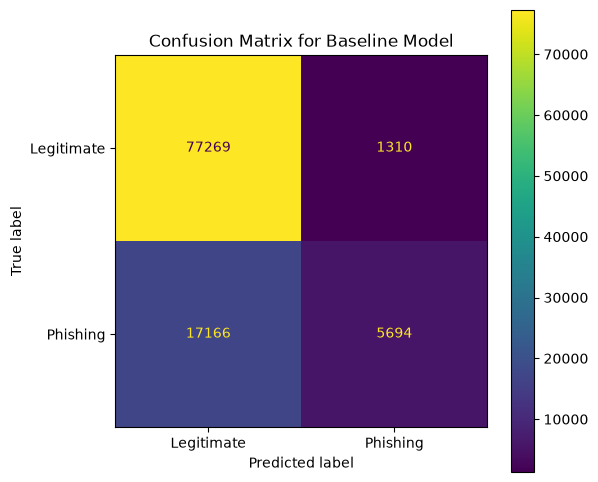

In [9]:
y_pred = model.predict(X_test)
print("\nBáo cáo Phân loại (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Legitimate (0)', 'Phishing (1)']))

print("\nMa trận Nhầm lẫn (Confusion Matrix):")
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, display_labels=['Legitimate', 'Phishing'])
plt.title("Confusion Matrix for Baseline Model")
plt.show()